## Loading needed libraries

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, coint
from statsmodels.tsa.vector_ar.vecm import coint_johansen, select_order, select_coint_rank


## Loading dataset

In [2]:
data = pd.read_csv('../data/raw/ready_merged_data_CO2.csv', parse_dates = ['Date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2801 entries, 0 to 2800
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          2801 non-null   datetime64[ns]
 1   target        2801 non-null   float64       
 2   Oil_price     2801 non-null   float64       
 3   Gas_price     2801 non-null   float64       
 4   Nasdaq_price  2801 non-null   float64       
 5   Coal_price    2801 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 131.4 KB


In [3]:
cols = data.columns.to_list()
cols = cols[1:]
cols

['target', 'Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']

In [4]:
df = data.copy()
df_log = np.log(df[cols])
df_log['Date'] = df['Date']

## Visualizations

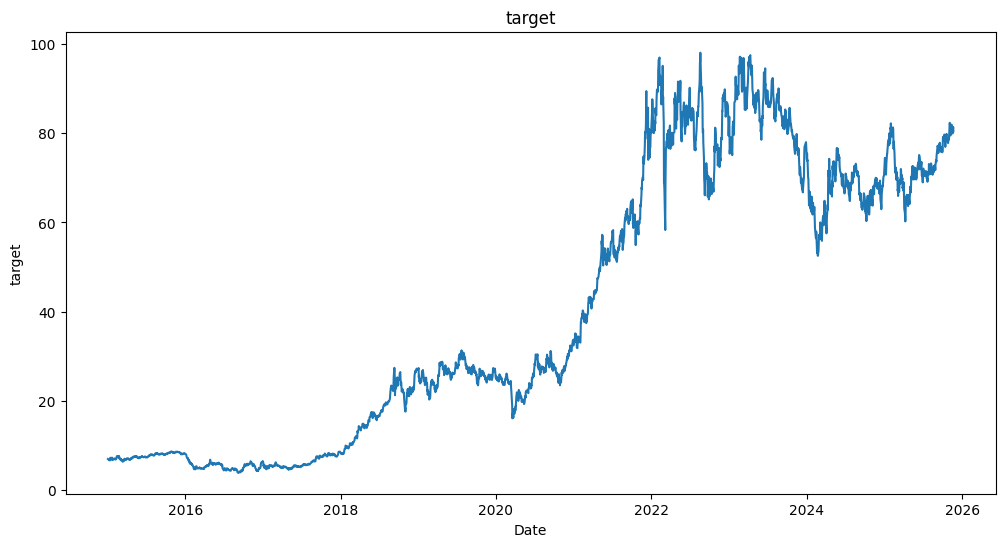

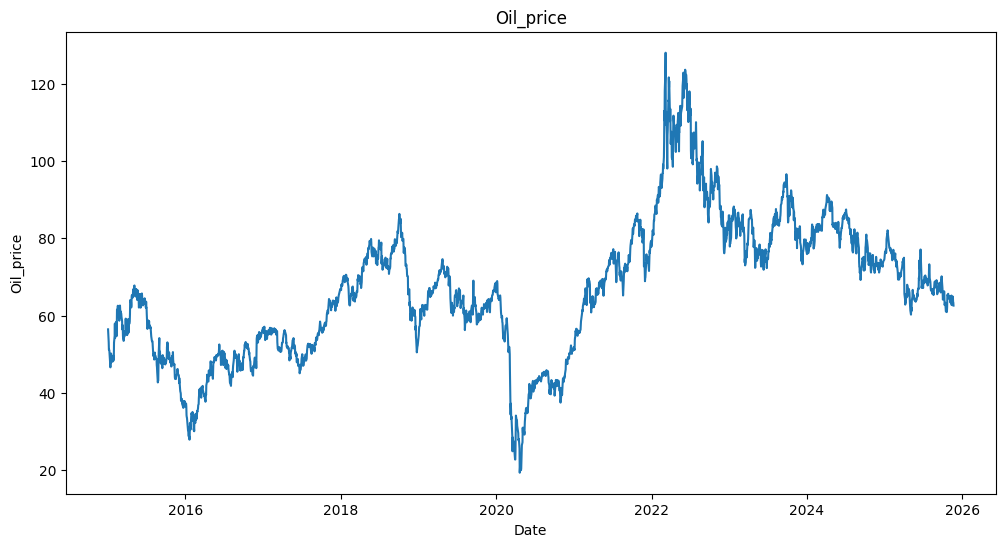

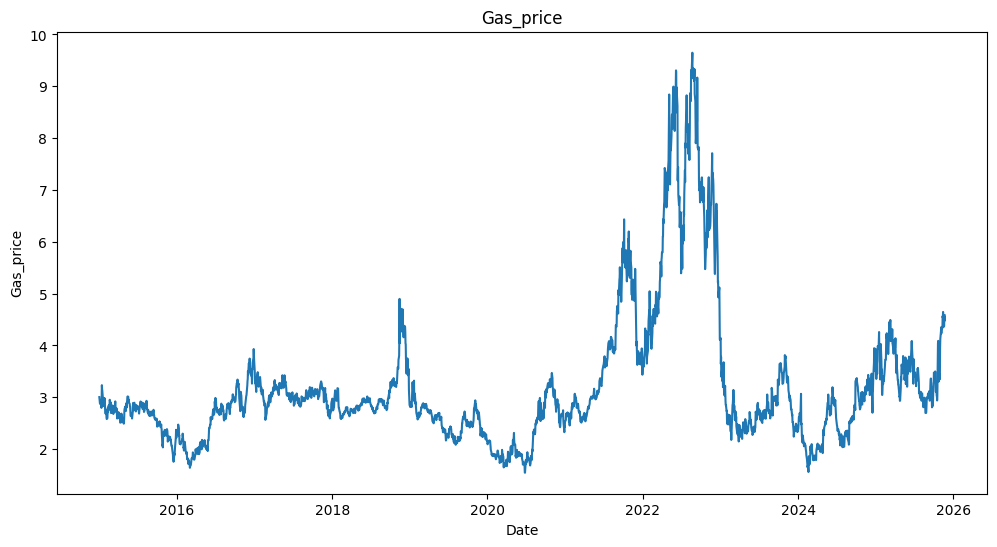

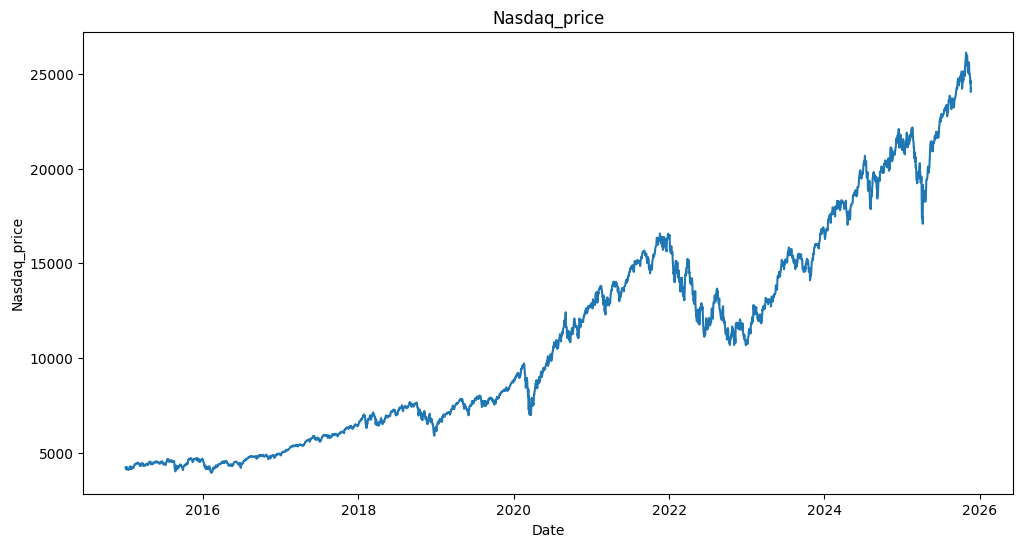

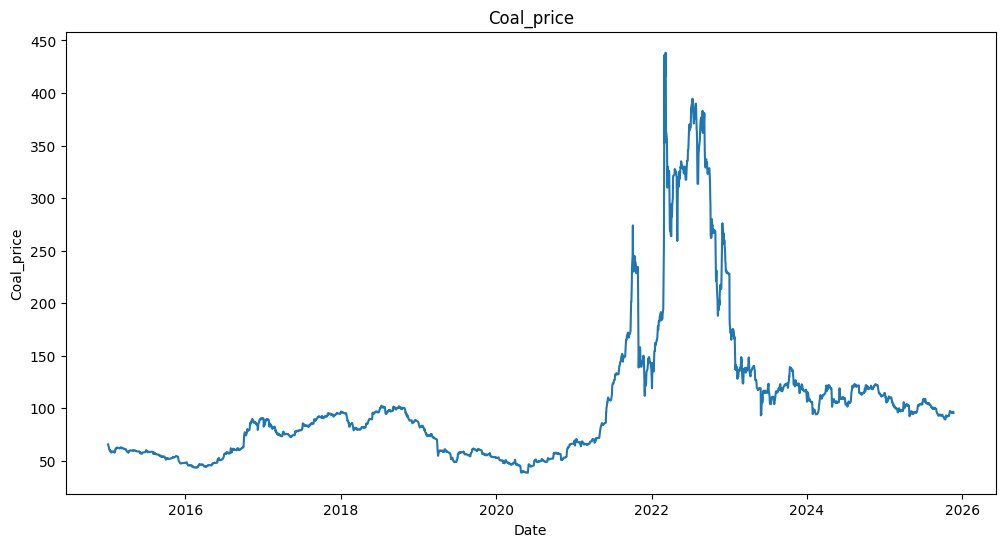

In [5]:
for col in cols: 
    plt.figure(figsize = (12, 6))
    plt.plot(df['Date'], df[col])
    plt.title(f'{col}')
    plt.xlabel('Date')
    plt.ylabel(f'{col}')
    plt.show()

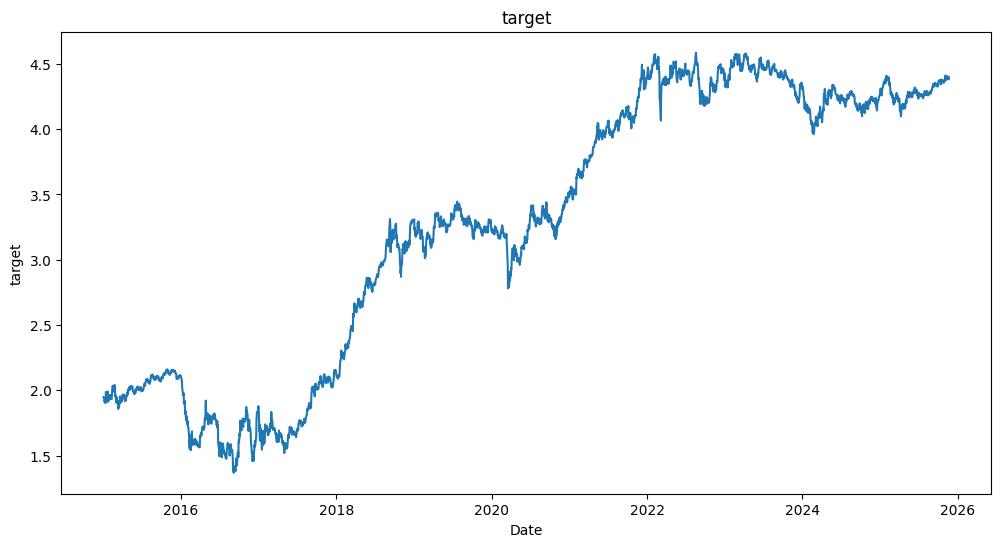

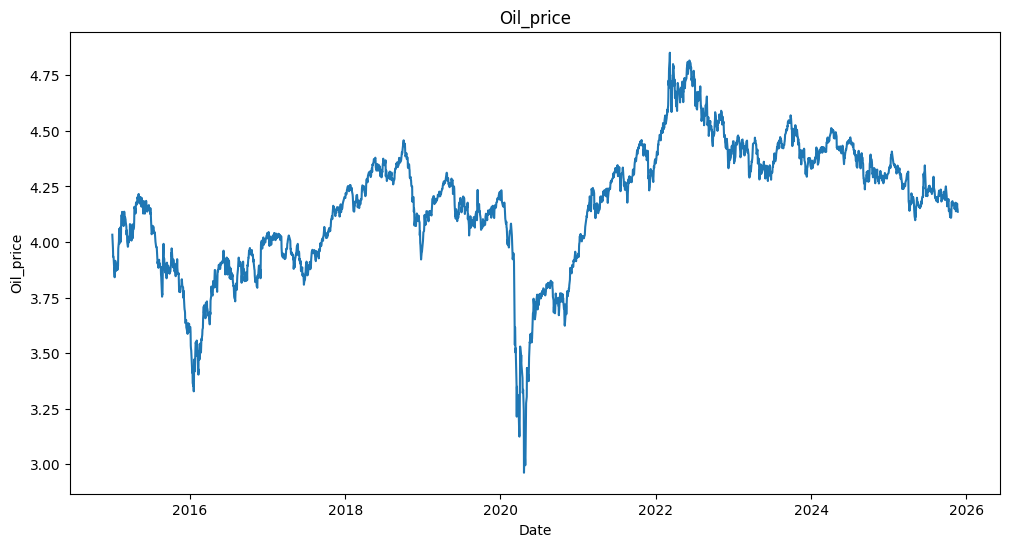

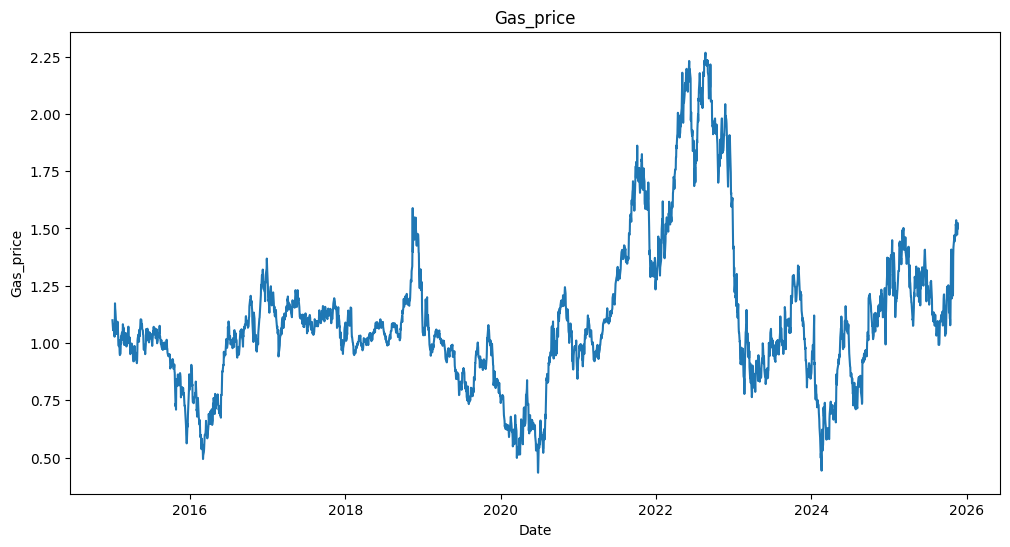

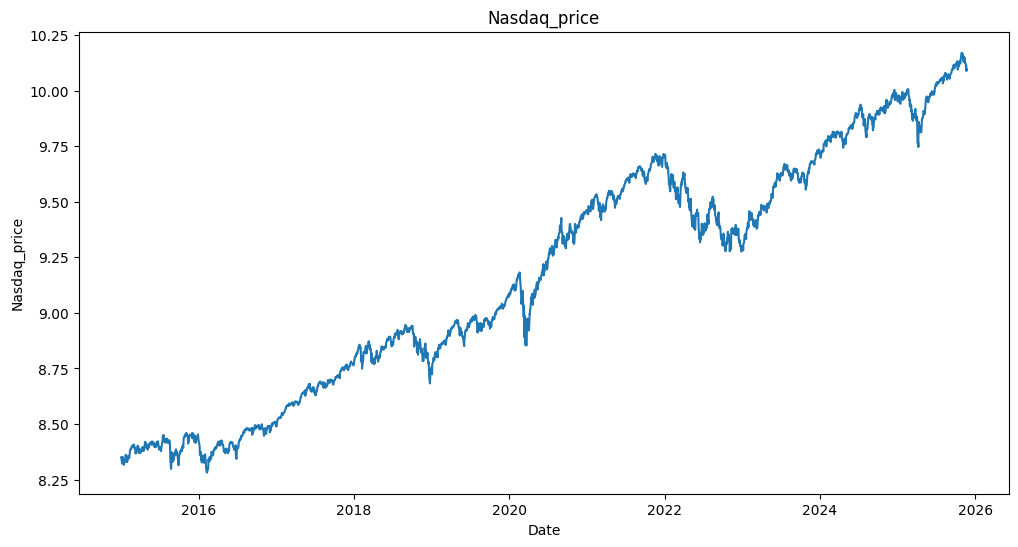

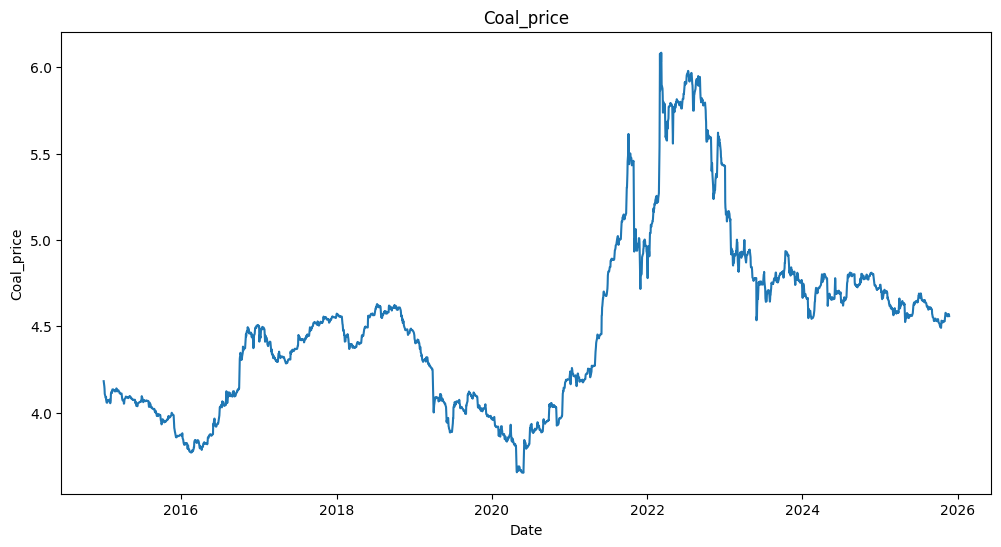

In [6]:
for col in cols: 
    plt.figure(figsize = (12, 6))
    plt.plot(df_log['Date'], df_log[col])
    plt.title(f'{col}')
    plt.xlabel('Date')
    plt.ylabel(f'{col}')
    plt.show()

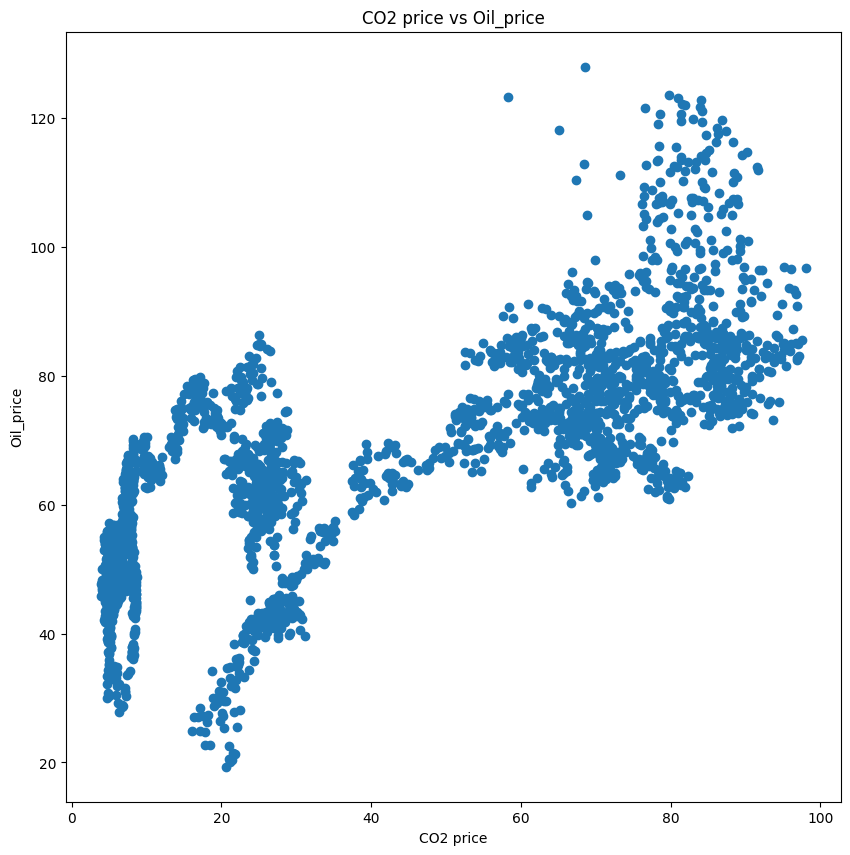

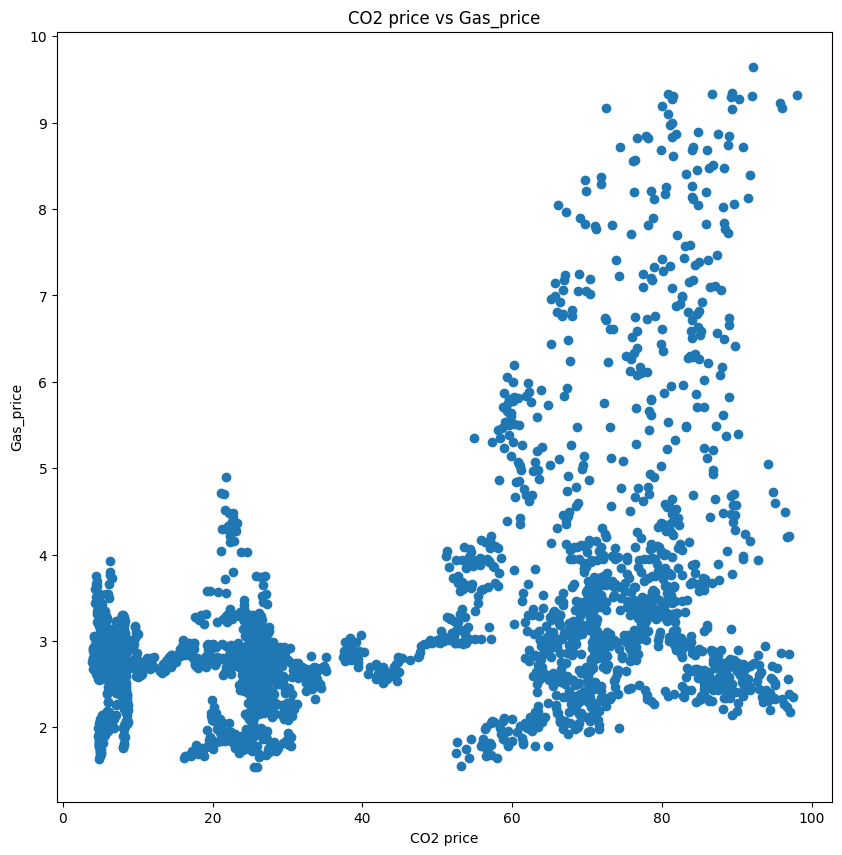

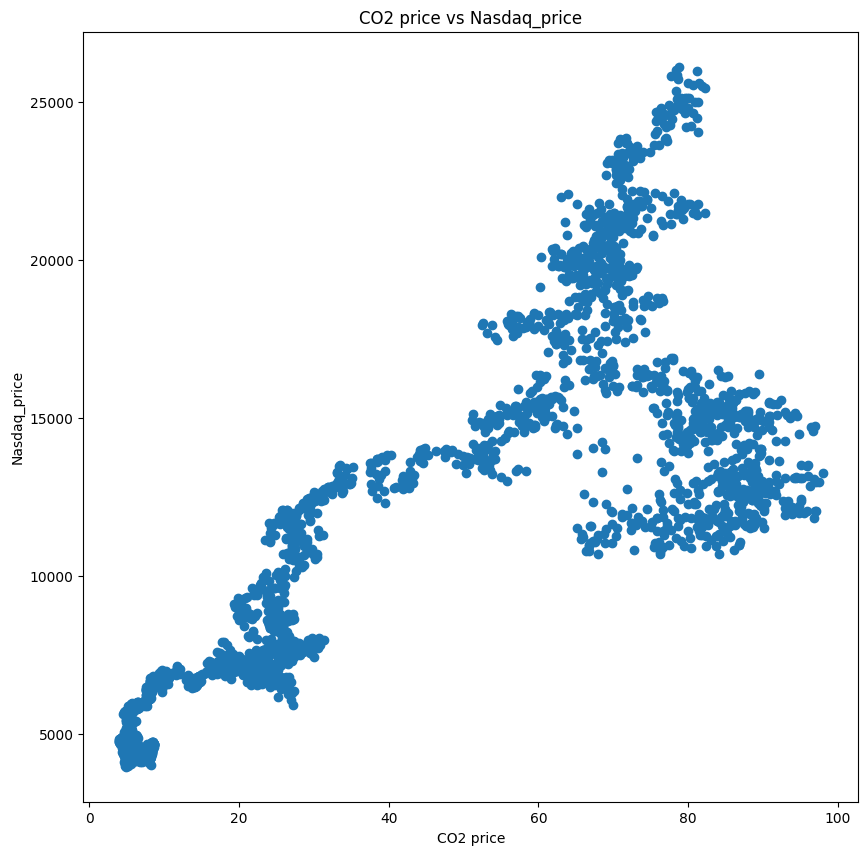

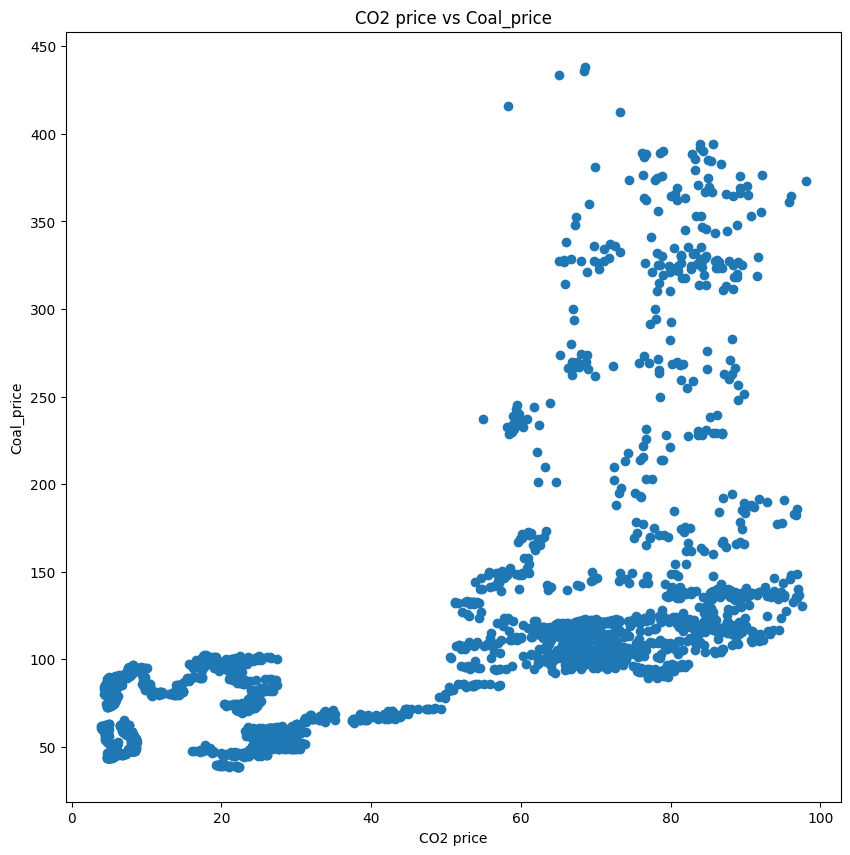

In [7]:
for col in cols: 
    if col != 'target':
        plt.figure(figsize = (10, 10))
        plt.scatter(df['target'], df[col])
        plt.title(f'CO2 price vs {col}')
        plt.xlabel('CO2 price')
        plt.ylabel(f'{col}')
        plt.show()

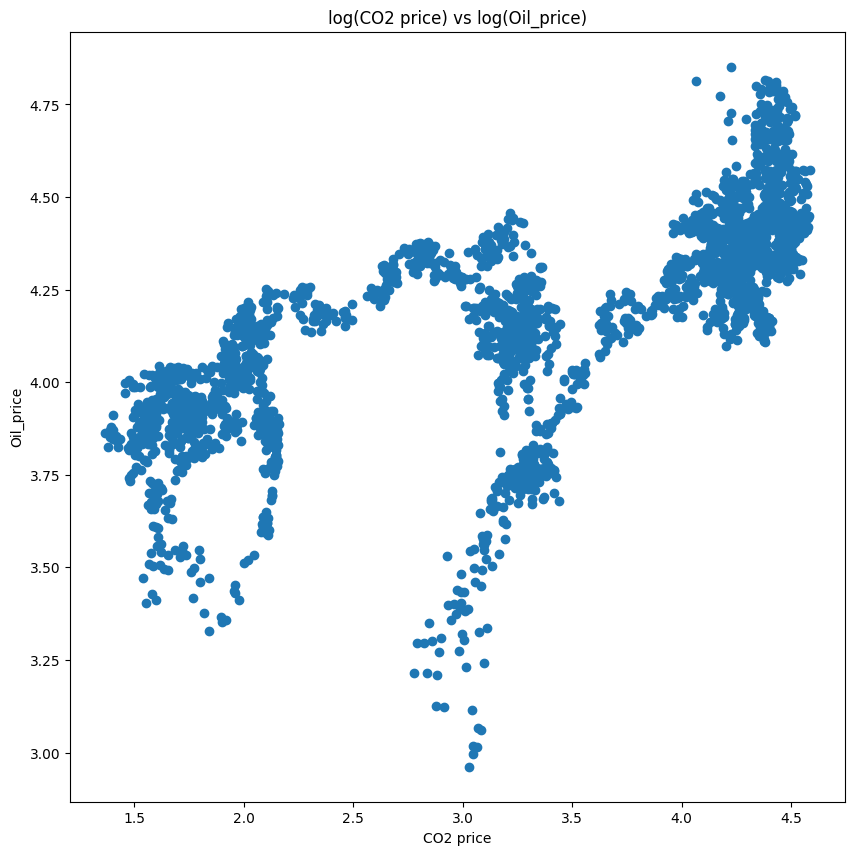

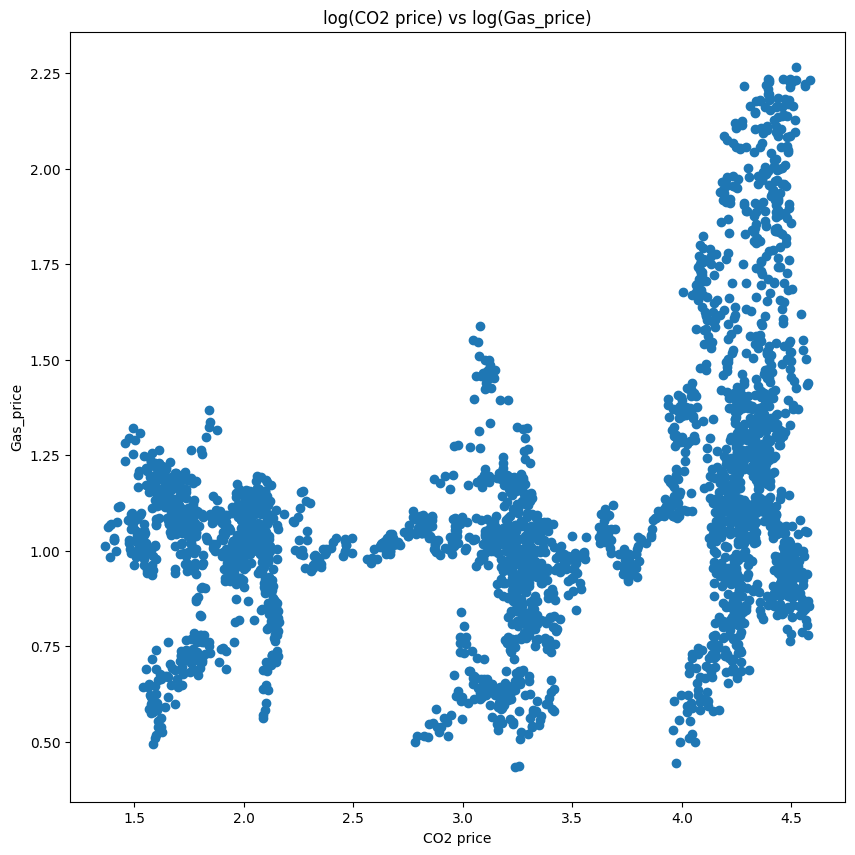

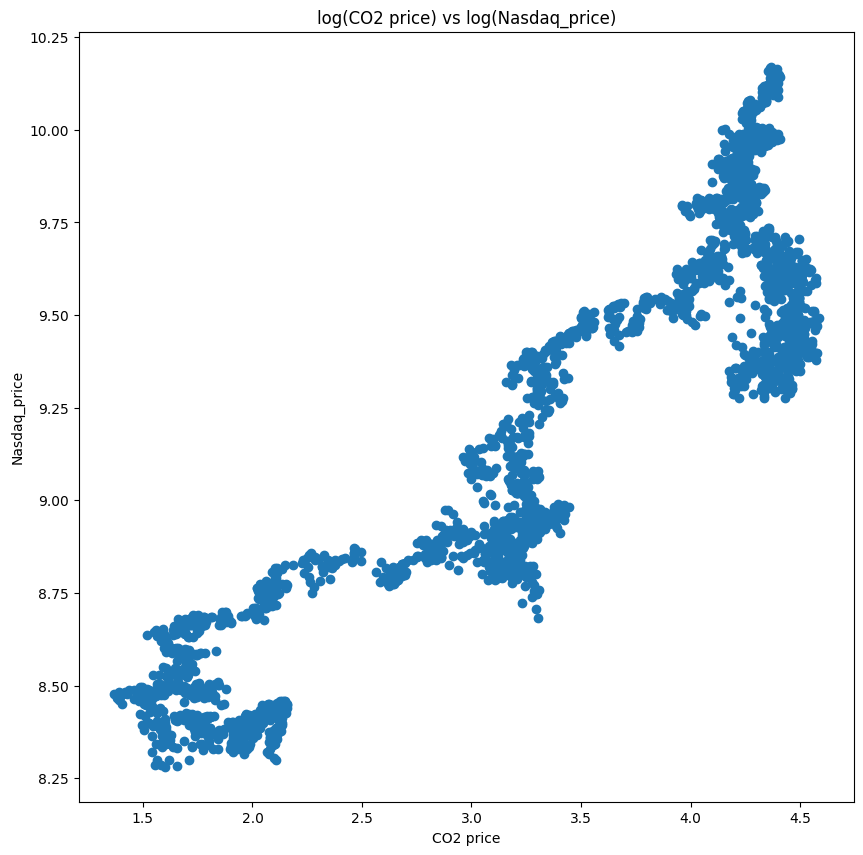

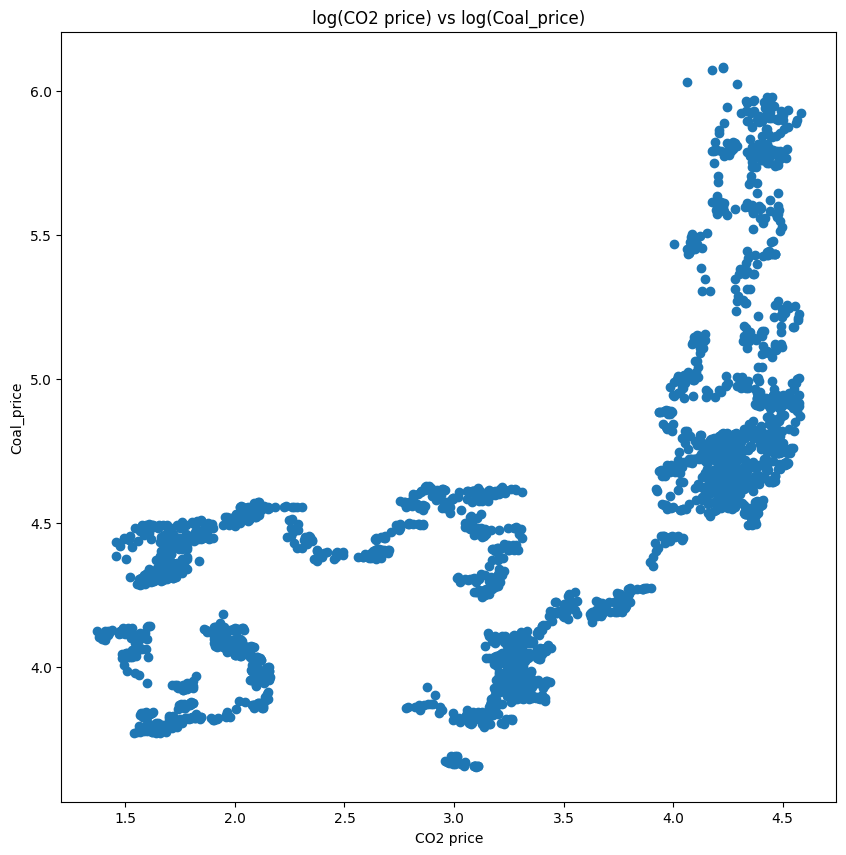

In [8]:
for col in cols: 
    if col != 'target':
        plt.figure(figsize = (10, 10))
        plt.scatter(df_log['target'], df_log[col])
        plt.title(f'log(CO2 price) vs log({col})')
        plt.xlabel('CO2 price')
        plt.ylabel(f'{col}')
        plt.show()

## Statistical tests

### Raw datasets

#### Augmented Dickey-Fuller test for stationarity

In [9]:
alpha = 0.01

print('LEVELS TIME-SERIES')
for col in cols: 
    print('*' * 50)
    print(f'col')
    adf_test = adfuller(df[col], result_object= True)
    p_value = adf_test[1]
    if p_value < alpha: 
        print(f'time series of {col} is stationary')
    else: 
        print(f'time series of {col} is not stationary (Has unit root)')
        
    print(f'p_value: {p_value}')
    

LEVELS TIME-SERIES
**************************************************
col
time series of target is not stationary (Has unit root)
p_value: 0.8652066477181262
**************************************************
col
time series of Oil_price is not stationary (Has unit root)
p_value: 0.22582871585433356
**************************************************
col
time series of Gas_price is not stationary (Has unit root)
p_value: 0.03269893437950028
**************************************************
col
time series of Nasdaq_price is not stationary (Has unit root)
p_value: 0.9925902218411569
**************************************************
col
time series of Coal_price is not stationary (Has unit root)
p_value: 0.3334723920295575


In [10]:
print('DIFFS TIME-SERIES')
for col in cols: 
    print('*' * 50)
    print(f'col')
    adf_test = adfuller(df[col].diff().dropna(), result_object= True)
    p_value = adf_test[1]
    if p_value < alpha: 
        print(f'time series of {col} is stationary')
    else: 
        print(f'time series of {col} is not stationary (Has unit root)')
        
    print(f'p_value: {p_value}')

DIFFS TIME-SERIES
**************************************************
col
time series of target is stationary
p_value: 6.39327355272285e-27
**************************************************
col
time series of Oil_price is stationary
p_value: 0.0
**************************************************
col
time series of Gas_price is stationary
p_value: 1.787005516850757e-19
**************************************************
col
time series of Nasdaq_price is stationary
p_value: 4.956128328940916e-18
**************************************************
col
time series of Coal_price is stationary
p_value: 1.2779284159024765e-25


RESULT: Levels are I(1) and differences are I(0)

### Logging the data then testing

In [11]:
alpha = 0.01

print('LEVELS TIME-SERIES')
for col in cols: 
    print('*' * 50)
    print(f'col')
    adf_test = adfuller(df_log[col], result_object= True)
    p_value = adf_test[1]
    if p_value < alpha: 
        print(f'time series of {col} is stationary')
    else: 
        print(f'time series of {col} is not stationary (Has unit root)')
        
    print(f'p_value: {p_value}')

LEVELS TIME-SERIES
**************************************************
col
time series of target is not stationary (Has unit root)
p_value: 0.7936366914209431
**************************************************
col
time series of Oil_price is not stationary (Has unit root)
p_value: 0.1575054608961149
**************************************************
col
time series of Gas_price is not stationary (Has unit root)
p_value: 0.15696138291858064
**************************************************
col
time series of Nasdaq_price is not stationary (Has unit root)
p_value: 0.9130374445616722
**************************************************
col
time series of Coal_price is not stationary (Has unit root)
p_value: 0.4593730678132705


In [12]:
print('DIFFS TIME-SERIES')
for col in cols: 
    print('*' * 50)
    print(f'col')
    adf_test = adfuller(df_log[col].diff().dropna(), result_object= True)
    p_value = adf_test[1]
    if p_value < alpha: 
        print(f'time series of {col} is stationary')
    else: 
        print(f'time series of {col} is not stationary (Has unit root)')
        
    print(f'p_value: {p_value}')

DIFFS TIME-SERIES
**************************************************
col
time series of target is stationary
p_value: 0.0
**************************************************
col
time series of Oil_price is stationary
p_value: 0.0
**************************************************
col
time series of Gas_price is stationary
p_value: 0.0
**************************************************
col
time series of Nasdaq_price is stationary
p_value: 1.0407877757412153e-29
**************************************************
col
time series of Coal_price is stationary
p_value: 0.0


RESULT: log(price) is I(1) and log-return is I(0)

We can perform cointegration testing


### Cointegration tests 

##### Raw data

Engle-Granger one variable test

In [13]:
alpha_coint = 0.05

print('LEVELS TIME-SERIES')
for col in cols: 
    if col != 'target': 
        print('*' * 50)
        print(f'col')
        coint_test = coint(df['target'], df[col], trend = 'ct', return_results= True)
        p_value = coint_test[1]
        if p_value < alpha: 
            print(f'Cointegration occurs between CO2 price and {col}')
        else: 
            print(f'Cointegration does not occur between CO2 price and {col}')

        print(f'p_value: {p_value}')

LEVELS TIME-SERIES
**************************************************
col
Cointegration does not occur between CO2 price and Oil_price
p_value: 0.19052092335286108
**************************************************
col
Cointegration does not occur between CO2 price and Gas_price
p_value: 0.4341082569342284
**************************************************
col
Cointegration does not occur between CO2 price and Nasdaq_price
p_value: 0.6846160868935804
**************************************************
col
Cointegration does not occur between CO2 price and Coal_price
p_value: 0.1317597670462275


Engle-Granger pairs test

In [14]:

pairs = [['Oil_price', 'Gas_price'], ['Nasdaq_price', 'Coal_price'], ['Oil_price', 'Nasdaq_price'], ['Oil_price', 'Coal_price'], ['Gas_price', 'Nasdaq_price'], ['Oil_price', 'Coal_price']]
coint_pairs = []

alpha_coint = 0.05

print('LEVELS TIME-SERIES PAIRS')
for pair in pairs: 
    if col != 'target': 
        print('*' * 50)
        print(f'col')
        coint_test = coint(df['target'], df[pair], trend = 'ctt', return_results= True)
        p_value = coint_test[1]
        if p_value < alpha: 
            print(f'Cointegration occurs between CO2 price and {pair}')
            coint_pairs.append(pair)
        else: 
            print(f'Cointegration does not occur between CO2 price and {pair}')

        print(f'p_value: {p_value}')
        
print(coint_pairs)

LEVELS TIME-SERIES PAIRS
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price']
p_value: 0.5591848571323959
**************************************************
col
Cointegration does not occur between CO2 price and ['Nasdaq_price', 'Coal_price']
p_value: 0.38966225388785963
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Nasdaq_price']
p_value: 0.4490157728142856
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Coal_price']
p_value: 0.3813754479519072
**************************************************
col
Cointegration does not occur between CO2 price and ['Gas_price', 'Nasdaq_price']
p_value: 0.6083982073739471
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Coal_price']
p_value: 0.3813754479519

EG all variables

In [15]:

alpha_coint = 0.05
all_vars = cols[1:]
print(all_vars)

coint_test = coint(df['target'], df[all_vars], trend = 'c', return_results= True)
p_value = coint_test[1]
if p_value < alpha: 
    print(f'Cointegration occurs between CO2 price and {all_vars}')
else: 
    print(f'Cointegration does not occur between CO2 price and {all_vars}')
print(f'p_value: {p_value}')

['Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']
Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']
p_value: 0.2011800651674367


EG energy variables only

In [16]:
alpha_coint = 0.05
# all_vars.remove('Nasdaq_price')
print(all_vars)

coint_test = coint(df['target'], df[all_vars], trend = 'ct', return_results= True)
p_value = coint_test[1]
if p_value < alpha: 
    print(f'Cointegration occurs between CO2 price and {all_vars}')
else: 
    print(f'Cointegration does not occur between CO2 price and {all_vars}')
print(f'p_value: {p_value}')

['Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']
Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']
p_value: 0.429480662390564


Johansen test

In [17]:

cols_johansen = ['target', 'Oil_price', 'Gas_price', 'Coal_price']
data_johansen = df[cols_johansen].dropna()

# Dobór liczby opóźnień w modelu VAR
lag_selection = select_order(
    data_johansen,
    maxlags=10,
    deterministic='ci'
)

print(lag_selection.summary())

# opóźnienia VAR
p = 7

# W teście Johansena podajemy liczbę opóźnień
# dla pierwszych różnic, czyli p - 1
rank_test = select_coint_rank(
    data_johansen,
    det_order=0,
    k_ar_diff=p-1,
    method='trace',
    signif=0.05
)

print(rank_test.summary())

 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       0.9053      0.9564       2.473      0.9238
1       0.8685     0.9535*       2.383      0.8992
2       0.8466      0.9657       2.332      0.8896
3       0.8337      0.9868       2.302      0.8889
4       0.8213       1.008       2.273      0.8888
5       0.8037       1.025       2.234      0.8835
6       0.7855       1.041       2.194     0.8776*
7      0.7770*       1.066      2.175*      0.8814
8       0.7832       1.107       2.189      0.9000
9       0.7780       1.135       2.177      0.9070
10      0.7811       1.172       2.184      0.9224
--------------------------------------------------
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   4          82.76          47.85
  1   4          19.58          29.80
-

##### Log data

Engle-Granger one variable test

In [18]:
alpha_coint = 0.05

print('LEVELS TIME-SERIES')
for col in cols: 
    if col != 'target': 
        print('*' * 50)
        print(f'col')
        coint_test = coint(df_log['target'], df_log[col], trend = 'c', return_results= True)
        p_value = coint_test[1]
        if p_value < alpha: 
            print(f'Cointegration occurs between CO2 price and {col}')
        else: 
            print(f'Cointegration does not occur between CO2 price and {col}')

        print(f'p_value: {p_value}')

LEVELS TIME-SERIES
**************************************************
col
Cointegration does not occur between CO2 price and Oil_price
p_value: 0.5833969627336826
**************************************************
col
Cointegration does not occur between CO2 price and Gas_price
p_value: 0.7482778031471221
**************************************************
col
Cointegration does not occur between CO2 price and Nasdaq_price
p_value: 0.7483539200394105
**************************************************
col
Cointegration does not occur between CO2 price and Coal_price
p_value: 0.8495259774186663


Engle-Granger pairs test

In [19]:
pairs = [['Oil_price', 'Gas_price'], ['Nasdaq_price', 'Coal_price'], ['Oil_price', 'Nasdaq_price'], ['Oil_price', 'Coal_price'], ['Gas_price', 'Nasdaq_price'], ['Oil_price', 'Coal_price']]
coint_pairs = []

alpha_coint = 0.05

print('LEVELS TIME-SERIES PAIRS')
for pair in pairs: 
    if col != 'target': 
        print('*' * 50)
        print(f'col')
        coint_test = coint(df_log['target'], df_log[pair], trend = 'ctt', return_results= True)
        p_value = coint_test[1]
        if p_value < alpha: 
            print(f'Cointegration occurs between CO2 price and {pair}')
            coint_pairs.append(pair)
        else: 
            print(f'Cointegration does not occur between CO2 price and {pair}')

        print(f'p_value: {p_value}')
        
print(coint_pairs)

LEVELS TIME-SERIES PAIRS
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price']
p_value: 0.7408898428796462
**************************************************
col
Cointegration does not occur between CO2 price and ['Nasdaq_price', 'Coal_price']
p_value: 0.8582168339812855
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Nasdaq_price']
p_value: 0.7323578401938244
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Coal_price']
p_value: 0.7199030397816674
**************************************************
col
Cointegration does not occur between CO2 price and ['Gas_price', 'Nasdaq_price']
p_value: 0.8881569461785361
**************************************************
col
Cointegration does not occur between CO2 price and ['Oil_price', 'Coal_price']
p_value: 0.71990303978166

Engle-Granger all variables test

In [20]:

alpha_coint = 0.05
all_vars = cols[1:]
print(all_vars)

coint_test = coint(df_log['target'], df_log[all_vars], trend = 'ct', return_results= True)
p_value = coint_test[1]
if p_value < alpha: 
    print(f'Cointegration occurs between CO2 price and {all_vars}')
else: 
    print(f'Cointegration does not occur between CO2 price and {all_vars}')
print(f'p_value: {p_value}')


['Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']
Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price', 'Nasdaq_price', 'Coal_price']
p_value: 0.9647072727111072


Energy variables only

In [21]:
alpha_coint = 0.05
all_vars.remove('Nasdaq_price')
print(all_vars)

coint_test = coint(df_log['target'], df_log[all_vars], trend = 'c', return_results= True)
p_value = coint_test[1]
if p_value < alpha: 
    print(f'Cointegration occurs between CO2 price and {all_vars}')
else: 
    print(f'Cointegration does not occur between CO2 price and {all_vars}')
print(f'p_value: {p_value}')

['Oil_price', 'Gas_price', 'Coal_price']
Cointegration does not occur between CO2 price and ['Oil_price', 'Gas_price', 'Coal_price']
p_value: 0.9494043306331262


Johansen test

In [22]:

cols_johansen_log = ['target', 'Oil_price', 'Gas_price', 'Coal_price']
data_johansen_log = df_log[cols_johansen_log].dropna()

# Dobór liczby opóźnień w modelu VAR
lag_selection = select_order(
    data_johansen_log,
    maxlags=10,
    deterministic='ci'
)

print(lag_selection.summary())

# opóźnienia VAR
p = 1

# W teście Johansena podajemy liczbę opóźnień
# dla pierwszych różnic, czyli p - 1
rank_test = select_coint_rank(
    data_johansen_log,
    det_order=0,
    k_ar_diff=p-1,
    method='trace',
    signif=0.05
)

print(rank_test.summary())

 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -28.60     -28.55*   3.798e-13      -28.58
1      -28.62*      -28.53  3.725e-13*     -28.59*
2       -28.62      -28.50   3.731e-13      -28.57
3       -28.62      -28.46   3.735e-13      -28.56
4       -28.61      -28.43   3.741e-13      -28.55
5       -28.61      -28.39   3.746e-13      -28.53
6       -28.61      -28.36   3.750e-13      -28.52
7       -28.61      -28.32   3.770e-13      -28.50
8       -28.60      -28.28   3.800e-13      -28.48
9       -28.59      -28.24   3.820e-13      -28.46
10      -28.59      -28.19   3.852e-13      -28.44
--------------------------------------------------
Johansen cointegration test using trace test statistic with 5% significance level
r_0 r_1 test statistic critical value
-------------------------------------
  0   4          63.78          47.85
  1   4          22.83          29.80
-